# Part 5 - Modelling and validation

BFT65B final report, walkthrough notebook. Every number below is read from `reports/` or recomputed live by the same scripts the README lists. Seed: `config.SEED = 42`.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

import pandas as pd
import polars as pl
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import config as C

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 80)
R = ROOT / "reports"
print("project root:", ROOT, "| python", sys.version.split()[0], "| polars", pl.__version__, "| seed", C.SEED)


def run(script, *args, tail=25):
    """Run one pipeline script exactly as the README does, and show the end of its output."""
    t = subprocess.run([sys.executable, script, *args], cwd=ROOT, capture_output=True, text=True,
                       encoding="utf-8", errors="replace", env={**os.environ, "PYTHONUTF8": "1"})
    lines = (t.stdout + t.stderr).strip().splitlines()
    print("\n".join(lines[-tail:]))
    print(f"\n>>> {script} {' '.join(args)} exited with {t.returncode}")
    assert t.returncode == 0, "step failed"


def csv(name, n=None):
    df = pd.read_csv(R / name)
    display(df if n is None else df.head(n))


def fig(name, width=820):
    display(Image(filename=str(R / name), width=width))

project root: D:\Final BigData | python 3.15.2 | polars 2.1.0 | seed 42


**Goal.** Baselines against our model under rolling time-ordered validation, metrics for rare events,
a threshold from estimated costs, a short Spark MLlib demo, and a single evaluation on the test period.

Model development (`p5_develop.py`, about 6 h) and the dry run (about 2.6 h) are not rerun here. The test
period was evaluated once; `p5_test.py --reproduce` reruns it and fails unless it equals the record.

### Cost of a false alarm and of a missed failure, from development data

In [2]:
print(json.dumps(json.loads((R / 'p5_costs.json').read_text()), indent=1))

{
 "loss_rate_median": 0.213001270071952,
 "loss_rate_failures": 2753,
 "cost_null_share": 0.008285302593659942,
 "median_loss_thousand": 11740.414,
 "mean_loss_thousand": 71116.94699114018,
 "share_saved_estimate": 0.23,
 "share_saved_range": [
  0.1,
  0.23,
  0.5
 ],
 "exam_person_weeks": 16,
 "median_exam_cost_thousand": 22.044759334233017,
 "exam_multipliers": [
  0.5,
  1,
  2,
  4
 ],
 "ratio_median_loss_to_exam": 532.5716566915959,
 "action_lag_days": 45
}


### Rolling validation: average precision per fold

In [3]:
csv('p5_cv_summary.csv')

,model,source,F1 crisis 1990-91,F2 quiet 1994-2006,F3 crisis 2008-11,mean_ap
0,B0 Texas ratio,"B0 Texas ratio, no fitting",0.2697,0.0759,0.5425,0.2960
1,"B1 logit, 3 ratios","B1 logit: capital, NPL, ROA",0.2942,0.1006,0.6018,0.3322
2,"Logit, all features",logit C=0.1,0.4421,0.1480,0.5882,0.3928
3,"GBM, with state features",gbm lr=0.03 leaves=15 trees=400,0.5466,0.1434,0.6508,0.4469
4,"GBM, no state (chosen)",gbm no state features,0.5332,0.1651,0.6610,0.4531


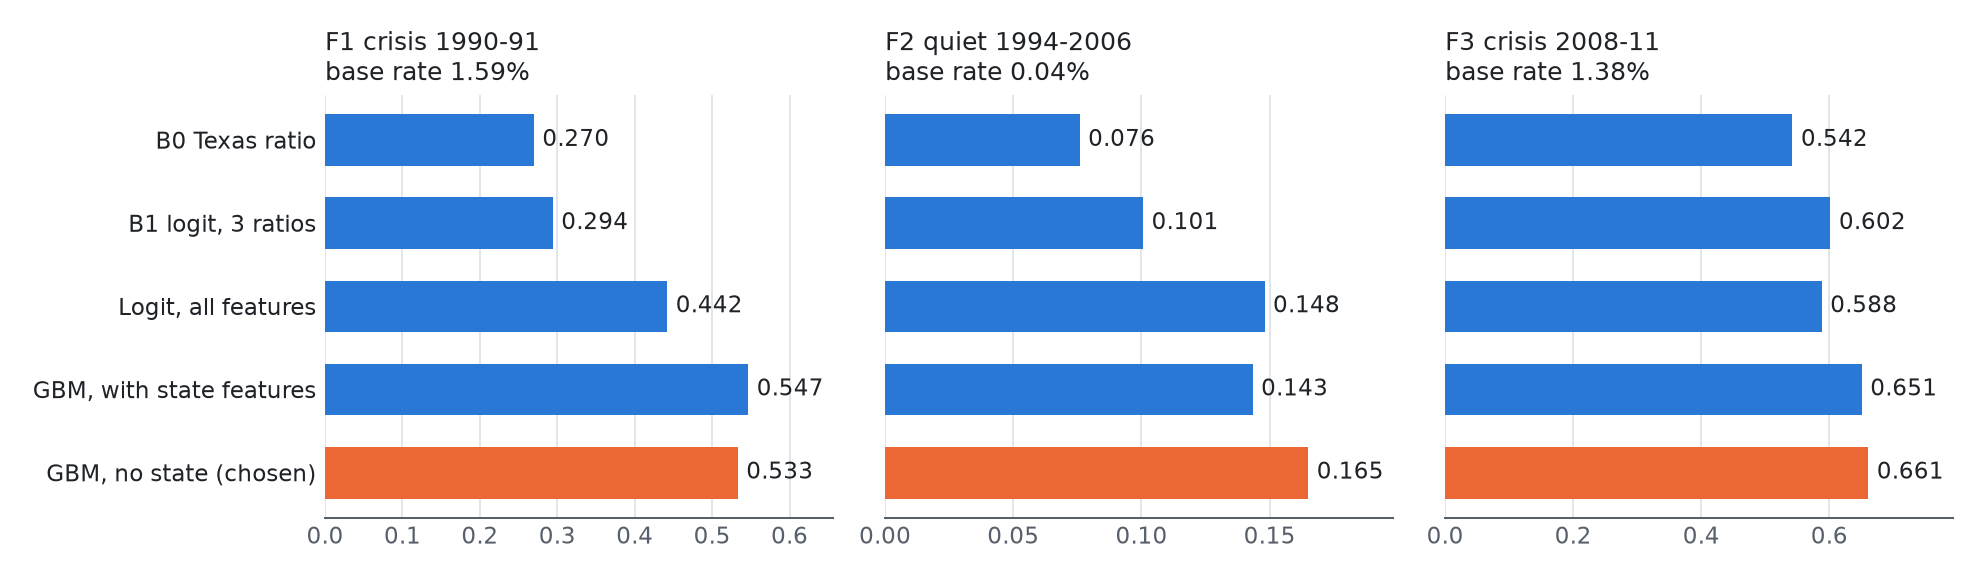

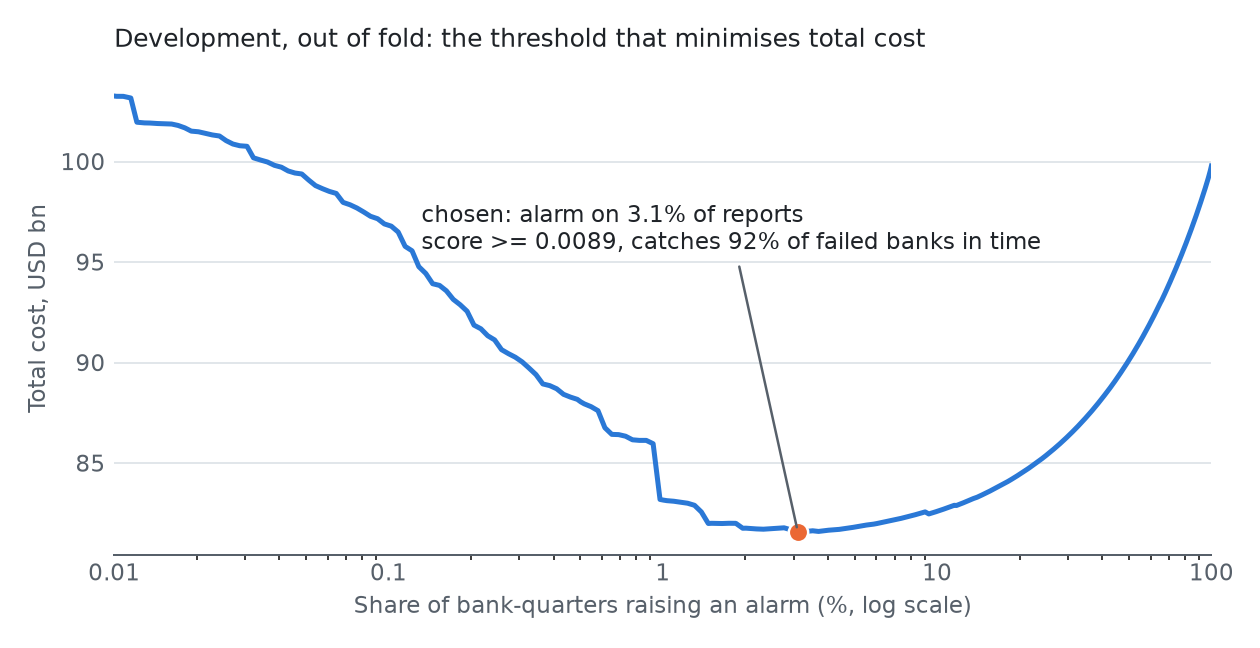

In [4]:
fig('fig_p5_cv.png'); fig('fig_p5_threshold.png')

### What was frozen before the test

In [5]:
print(json.dumps(json.loads((R / 'p5_frozen.json').read_text()), indent=1)[:1200])

{
 "chosen": {
  "name": "gbm no state features",
  "kind": "hgb",
  "lr": 0.03,
  "leaves": 15,
  "iters": 400,
  "features": [
   "eq_ta",
   "eq_ta_d4",
   "npl",
   "texas",
   "res_cov",
   "res_ln",
   "nco_4q",
   "prov_4q",
   "npl_d4",
   "npl_st_gap",
   "con_ln",
   "ln_ta",
   "ln_g4",
   "roa_4q",
   "roa_q_d4",
   "cost_inc",
   "roa_std8",
   "loss_q4",
   "liq_ta",
   "bro_dep",
   "asset_g4",
   "f_neg_equity"
  ]
 },
 "threshold": 0.008922758744692224,
 "capacity_share": 0.01,
 "action_lag_days": 45,
 "share_saved": 0.23,
 "train_window": [
  "1986-03-31",
  "2011-12-31"
 ],
 "train_rows": 1203457,
 "train_y1": 9488,
 "models_sha256": "bdc88c929ff46a2ad99fa11634de30ee9977e1c8ce2d509e6b7799ea40bc55d2",
 "selection_mean_ap": 0.45306619684025157,
 "best_candidate_mean_ap": 0.45306619684025157,
 "dev_oof": {
  "alarm_share": 0.031079596295380443,
  "bank_recall": 0.9227642276422764,
  "total_cost_thousand": 81566933.97270323,
  "no_model_cost_thousand": 103848485.67342848

### Spark MLlib demo against scikit-learn on the same fold

In [6]:
csv('p5_spark_mllib.csv')

,engine,fit_s,ap,roc_auc,rows_train,rows_val
0,Spark logistic,35.8,0.59116,0.97753,1041927,127181
1,"Spark GBT, 30 trees, depth 4",40.7,0.63296,0.97101,1041927,127181
2,scikit-learn logistic,7.4,0.58949,0.97731,1041927,127181


### The single test evaluation, reproduced and compared with the record (live, about 3 min)

In [7]:
run('src/p5_test.py', '--reproduce')

   ],
   "B0": [
    0.18140708605886455,
    0.31389251875752766
   ]
  },
  "top_row_recall_ci95": [
   0.7083124811934814,
   0.8815267882587631
  ],
  "resamples": 500,
  "unit": "bank"
 }
}
shape: (3, 9)
┌─────────────────────────────┬────────────┬────────┬──────────┬─────────┬───────────────┬────────────────┬─────────────────┬────────────────────────────┐
│ model                       ┆ prevalence ┆ ap     ┆ lift     ┆ roc_auc ┆ top_precision ┆ top_row_recall ┆ top_bank_recall ┆ top_bank_recall_actionable │
│ ---                         ┆ ---        ┆ ---    ┆ ---      ┆ ---     ┆ ---           ┆ ---            ┆ ---             ┆ ---                        │
│ str                         ┆ f64        ┆ f64    ┆ f64      ┆ f64     ┆ f64           ┆ f64            ┆ f64             ┆ f64                        │
╞═════════════════════════════╪════════════╪════════╪══════════╪═════════╪═══════════════╪════════════════╪═════════════════╪════════════════════════════╡
│ gbm no state f

In [8]:
csv('p5_test_metrics.csv')

,model,rows,y1,failed_banks,prevalence,ap,lift,roc_auc,top_precision,top_row_recall,top_bank_recall,top_bank_recall_actionable,brier,log_loss,mean_pred,observed
0,gbm no state features,274032,254,78,0.00093,0.34547,372.71469,0.93798,0.07336,0.79921,0.87179,0.75641,0.00074,0.00361,0.00126,0.00093
1,"B1 logit: capital, NPL, ROA",274032,254,78,0.00093,0.31774,342.80060,0.95963,0.07228,0.78740,0.85897,0.74359,0.00077,0.00442,0.00175,0.00093
2,"B0 Texas ratio, no fitting",274032,254,78,0.00093,0.09587,103.43065,0.90268,0.06072,0.66142,0.79487,0.67949,NaN,NaN,NaN,NaN


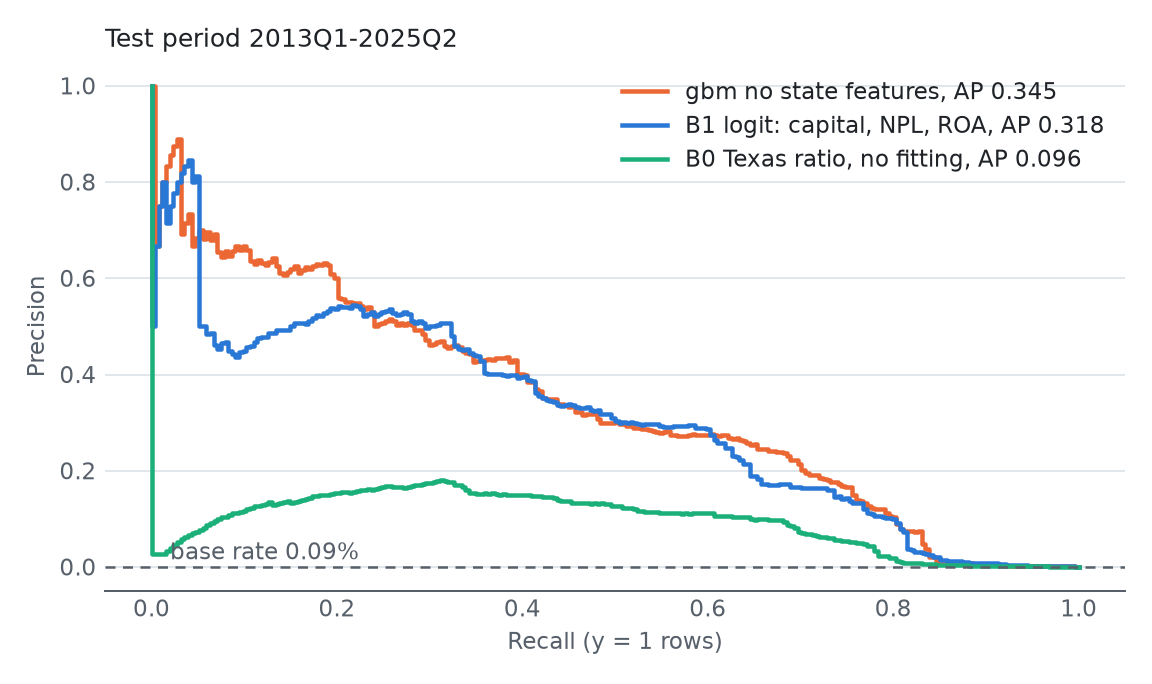

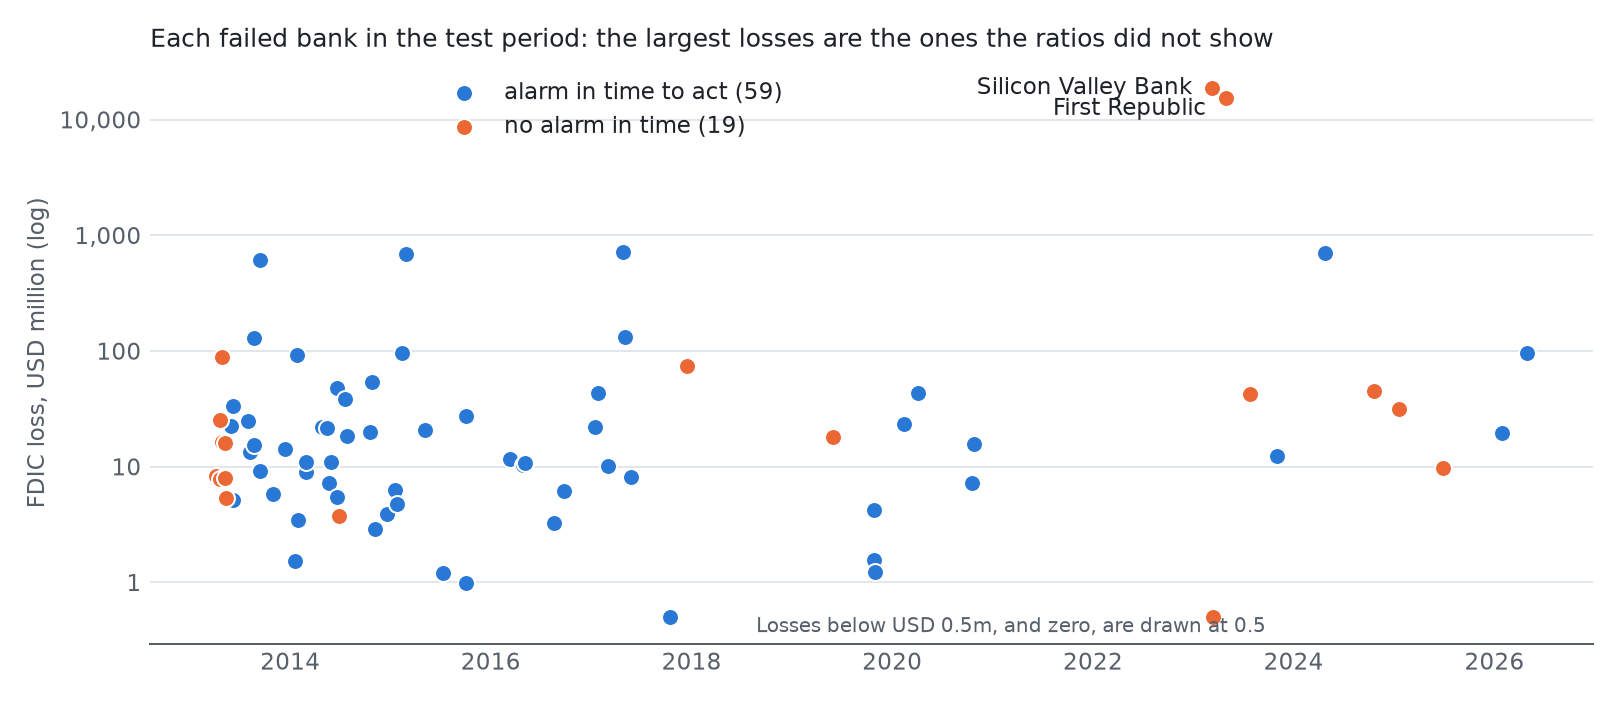

In [9]:
fig('fig_p5_test_pr.png'); fig('fig_p5_test_banks.png')

### Validation design tests (live)

In [10]:
run('src/p5_checks.py')

[PASS] F1 crisis 1990-91: 4-quarter gap, validation after training, inside development  gap 4
[PASS] F2 quiet 1994-2006: 4-quarter gap, validation after training, inside development  gap 4
[PASS] F3 crisis 2008-11: 4-quarter gap, validation after training, inside development  gap 4
[PASS] only p5_test.py asks for the test period  ['p5_test.py']
[PASS] saved models match the frozen hash  bdc88c929ff4
[PASS] the frozen training window ends with development  
[PASS] the recorded results match their lock  2026-11-07T18:09:25.770741+00:00
[PASS] the frozen model and threshold are the ones the test used  0.008923
[PASS] a second test run is refused  
[PASS] control: with shuffled training labels, AP collapses far below the real model  prevalence 0.0138, shuffled 0.0153, real 0.5895
[PASS] cost model: worked example at t = 0.8  1270.0
[PASS] cost model: an alarm inside the action lag does not count as caught  alarms 3
[PASS] cost model: with no lag the same alarm counts  
[PASS] cost model: a

In [11]:
csv('p5_checks.csv')

,test,result,detail
0,"F1 crisis 1990-91: 4-quarter gap, validation after training, inside development",PASS,gap 4
1,"F2 quiet 1994-2006: 4-quarter gap, validation after training, inside develop...",PASS,gap 4
2,"F3 crisis 2008-11: 4-quarter gap, validation after training, inside development",PASS,gap 4
3,only p5_test.py asks for the test period,PASS,['p5_test.py']
4,saved models match the frozen hash,PASS,bdc88c929ff4
5,the frozen training window ends with development,PASS,NaN
6,the recorded results match their lock,PASS,2026-11-07T18:09:25.770741+00:00
7,the frozen model and threshold are the ones the test used,PASS,0.008923
8,a second test run is refused,PASS,NaN
9,"control: with shuffled training labels, AP collapses far below the real model",PASS,"prevalence 0.0138, shuffled 0.0153, real 0.5895"
